<a href="https://colab.research.google.com/github/manikanta-eng/arvr-project/blob/main/tabnet_pm2%2C5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Reading file: /content/Data.xlsx

DATASET SUMMARY
Original rows       : 2183
Rows with missing data: 12
Complete rows used  : 2171
Input variables     : RH, WD, SR, BP, AT
Target variable     : PM2.5

Descriptive Statistics:


,PM2.5,RH,WD,SR,BP,AT
count,2171.000,2171.000,2171.000,2171.000,2171.000,2171.000
mean,147.220,65.802,159.622,126.858,737.633,15.035
std,72.652,15.574,67.765,142.873,6.284,2.755
min,1.000,36.000,7.000,2.000,726.000,11.000
25%,95.000,51.000,113.000,5.000,730.000,13.000
50%,139.000,68.000,153.000,5.000,740.000,15.000
75%,190.500,79.000,211.500,307.500,742.000,17.000
max,427.000,95.000,332.000,334.000,749.000,23.000


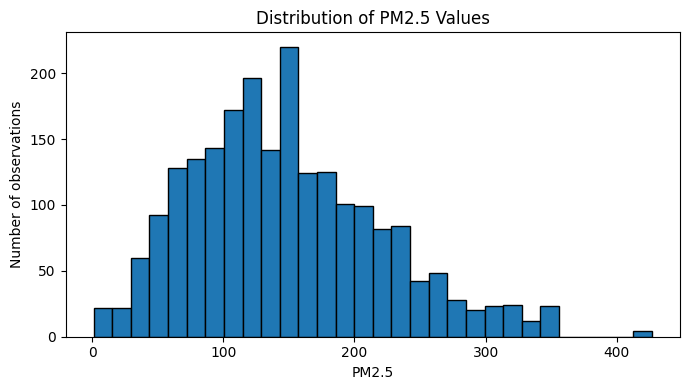


DATA SPLIT
-------------------------------------------------------
Training   : 1519 rows (70.0%)
Validation : 326 rows (15.0%)
Testing    : 326 rows (15.0%)

TRAINING TABNET MODEL
epoch 0  | loss: 26438.45169| train_rmse: 222.17923| valid_rmse: 228.56871|  0:00:00s
epoch 10 | loss: 4834.34304| train_rmse: 498.74478| valid_rmse: 479.4089|  0:00:02s
epoch 20 | loss: 3058.99031| train_rmse: 347.90986| valid_rmse: 354.87383|  0:00:05s
epoch 30 | loss: 2852.28276| train_rmse: 184.1288| valid_rmse: 184.52388|  0:00:07s
epoch 40 | loss: 2539.68247| train_rmse: 154.87523| valid_rmse: 156.39836|  0:00:10s

Early stopping occurred at epoch 41 with best_epoch = 26 and best_valid_rmse = 63.05993

FINAL TABNET TEST RESULTS


,Metric,Test Result,Meaning
0,MSE,4510.4961,Lower is better
1,MAE,56.2438,Lower is better
2,MAPE (%),128.3741,Lower is better
3,RMSE,67.1602,Lower is better
4,R²,0.1372,Closer to 1 is generally better


Test observations: 326
Actual PM2.5 mean: 148.5368
Predicted PM2.5 mean: 171.6121
Interpretation: Limited fit; further improvement may help.

SAMPLE PREDICTIONS


,Actual_PM2.5,Predicted_PM2.5,Absolute_Error
0,79.0,110.811996,31.812000
1,196.0,227.401993,31.402000
2,218.0,126.228996,91.771004
3,290.0,256.372986,33.626999
4,158.0,190.850006,32.849998
5,72.0,226.412003,154.412003
6,240.0,202.539001,37.460999
7,189.0,244.828003,55.827999
8,40.0,115.001999,75.001999
9,149.0,190.942001,41.942001


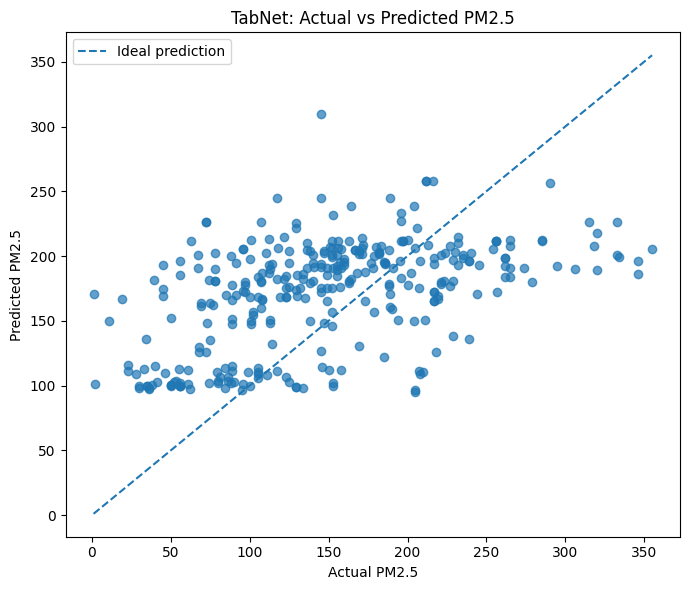

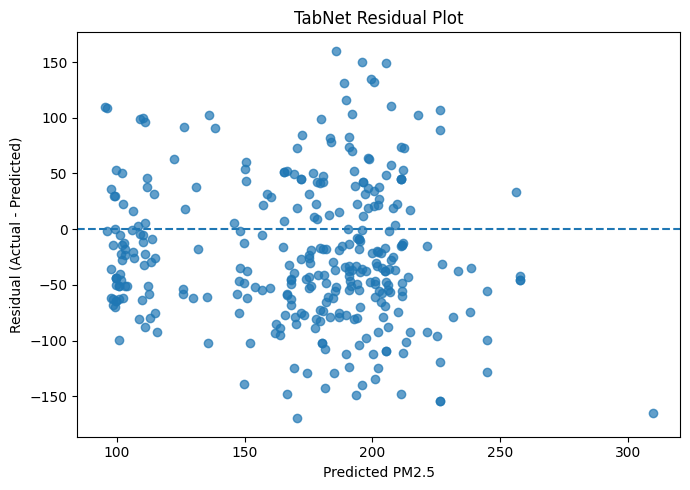

Successfully saved model at /content/tabnet_results/tabnet_pm25_model.zip

Results folder: /content/tabnet_results
Includes metrics, predictions, saved model, and graphs.
Download ZIP file: /content/tabnet_pm25_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%pip -q install pytorch-tabnet openpyxl

import os
import re
import random
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from pytorch_tabnet.tab_model import TabNetRegressor

warnings.filterwarnings("ignore")

# 1. SETTINGS
SEED = 42
TARGET = "PM2.5"
FEATURES = ["RH", "WD", "SR", "BP", "AT"]
OUTPUT_DIR = "/content/tabnet_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

# 2. UPLOAD EXCEL FILE
from google.colab import files

if not os.path.exists("/content/Data.xlsx"):
    print("Upload your Data.xlsx Excel file:")
    uploaded = files.upload()

    excel_files = [
        name for name in uploaded
        if name.lower().endswith((".xlsx", ".xls"))
    ]

    if not excel_files:
        raise ValueError("Please upload an Excel file (.xlsx or .xls).")

    DATA_FILE = excel_files[0]
else:
    DATA_FILE = "/content/Data.xlsx"

print("\nReading file:", DATA_FILE)

# 3. LOAD AND CHECK DATA
raw = pd.read_excel(DATA_FILE)
raw.columns = [str(c).strip() for c in raw.columns]

def normalize_column(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

aliases = {
    "PM2.5": ["pm25", "pm2", "pm25concentration", "pm25value"],
    "RH": ["rh", "relativehumidity"],
    "WD": ["wd", "winddirection"],
    "SR": ["sr", "solarradiation"],
    "BP": [
        "bp", "barometricpressure", "biometricpressure",
        "airpressure", "pressure"
    ],
    "AT": ["at", "airtemperature", "temperature"]
}

column_lookup = {}
for col in raw.columns:
    normalized = normalize_column(col)
    for standard_name, possible_names in aliases.items():
        if normalized in possible_names:
            column_lookup.setdefault(standard_name, col)

missing_columns = [
    col for col in [TARGET] + FEATURES
    if col not in column_lookup
]

if missing_columns:
    print("\nColumns found in Excel:")
    print(raw.columns.tolist())
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        "Check your Excel column headings."
    )

df = pd.DataFrame({
    standard_name: raw[original_name]
    for standard_name, original_name in column_lookup.items()
})

df = df[[TARGET] + FEATURES].copy()

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

original_rows = len(df)
missing_rows = int(df.isna().any(axis=1).sum())
df = df.dropna().reset_index(drop=True)

if len(df) < 30:
    raise ValueError(
        f"Only {len(df)} complete rows are available. "
        "At least 30 rows are recommended."
    )

if df[TARGET].nunique() < 2:
    raise ValueError("PM2.5 must contain at least two distinct values.")

# 4. DATASET SUMMARY
print("\n" + "=" * 55)
print("DATASET SUMMARY")
print("=" * 55)
print("Original rows       :", original_rows)
print("Rows with missing data:", missing_rows)
print("Complete rows used  :", len(df))
print("Input variables     :", ", ".join(FEATURES))
print("Target variable     :", TARGET)

print("\nDescriptive Statistics:")
display(df.describe().round(3))

# Class distribution is not applicable to regression.
# Show distributions of the continuous target instead.
plt.figure(figsize=(7, 4))
plt.hist(df[TARGET], bins=30, edgecolor="black")
plt.xlabel("PM2.5")
plt.ylabel("Number of observations")
plt.title("Distribution of PM2.5 Values")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pm25_distribution.png", dpi=200)
plt.show()

# 5. SPLIT: 70% TRAIN, 15% VALIDATION, 15% TEST
X = df[FEATURES].to_numpy(dtype=np.float32)
y = df[[TARGET]].to_numpy(dtype=np.float32)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("\nDATA SPLIT")
print("-" * 55)
print(f"Training   : {len(X_train)} rows ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation : {len(X_val)} rows ({len(X_val)/len(df)*100:.1f}%)")
print(f"Testing    : {len(X_test)} rows ({len(X_test)/len(df)*100:.1f}%)")

# 6. CREATE TABNET MODEL
model = TabNetRegressor(
    n_d=16,
    n_a=16,
    n_steps=3,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    seed=SEED,
    verbose=10
)

# 7. TRAIN THE MODEL
print("\n" + "=" * 55)
print("TRAINING TABNET MODEL")
print("=" * 55)

batch_size = min(256, len(X_train))
virtual_batch_size = min(64, batch_size)

model.fit(
    X_train=X_train,
    y_train=y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    eval_name=["train", "valid"],
    eval_metric=["rmse"],
    max_epochs=100,
    patience=15,
    batch_size=batch_size,
    virtual_batch_size=virtual_batch_size,
    num_workers=0,
    drop_last=False
)

# 8. PREDICT ON UNSEEN TEST DATA
predicted = model.predict(X_test).reshape(-1)
actual = y_test.reshape(-1)

mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual, predicted)
r2 = r2_score(actual, predicted)

# MAPE is undefined for zero actual values.
nonzero = np.abs(actual) > 1e-8
if np.any(nonzero):
    mape = np.mean(
        np.abs((actual[nonzero] - predicted[nonzero]) /
               actual[nonzero])
    ) * 100
else:
    mape = np.nan

# 9. DISPLAY CLEAR RESULTS
results = pd.DataFrame({
    "Metric": ["MSE", "MAE", "MAPE (%)", "RMSE", "R²"],
    "Test Result": [mse, mae, mape, rmse, r2],
    "Meaning": [
        "Lower is better",
        "Lower is better",
        "Lower is better",
        "Lower is better",
        "Closer to 1 is generally better"
    ]
})

print("\n" + "=" * 65)
print("FINAL TABNET TEST RESULTS")
print("=" * 65)
display(results.round(4))

print(f"Test observations: {len(actual)}")
print(f"Actual PM2.5 mean: {np.mean(actual):.4f}")
print(f"Predicted PM2.5 mean: {np.mean(predicted):.4f}")

if r2 >= 0.75:
    print("Interpretation: Strong fit on this test split.")
elif r2 >= 0.50:
    print("Interpretation: Moderate fit on this test split.")
elif r2 >= 0:
    print("Interpretation: Limited fit; further improvement may help.")
else:
    print("Interpretation: Poor test fit; investigate features and model settings.")

# 10. SAVE METRICS AND PREDICTIONS
results.to_csv(
    f"{OUTPUT_DIR}/results_metrics.csv", index=False
)

prediction_df = pd.DataFrame({
    "Actual_PM2.5": actual,
    "Predicted_PM2.5": predicted,
    "Absolute_Error": np.abs(actual - predicted)
})

prediction_df.to_csv(
    f"{OUTPUT_DIR}/test_predictions.csv", index=False
)

print("\nSAMPLE PREDICTIONS")
display(prediction_df.head(10).round(3))

# 11. ACTUAL VS PREDICTED GRAPH
plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.7)

lower = min(float(actual.min()), float(predicted.min()))
upper = max(float(actual.max()), float(predicted.max()))

if lower == upper:
    upper = lower + 1

plt.plot(
    [lower, upper], [lower, upper],
    linestyle="--", label="Ideal prediction"
)
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("TabNet: Actual vs Predicted PM2.5")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/actual_vs_predicted.png", dpi=200)
plt.show()

# 12. RESIDUAL GRAPH
residuals = actual - predicted

plt.figure(figsize=(7, 5))
plt.scatter(predicted, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted PM2.5")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("TabNet Residual Plot")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/residual_plot.png", dpi=200)
plt.show()

# 13. TRAINING HISTORY GRAPH
history = getattr(model, "history", None)

if history is not None and hasattr(history, "keys"):
    plt.figure(figsize=(8, 5))
    plotted = False

    for key in history.keys():
        values = history[key]
        if len(values) > 0:
            plt.plot(values, label=str(key))
            plotted = True

    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("RMSE")
        plt.title("TabNet Training History")
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/training_history.png", dpi=200)
        plt.show()
    else:
        plt.close()

# 14. SAVE TRAINED MODEL
model.save_model(f"{OUTPUT_DIR}/tabnet_pm25_model")

# 15. PACKAGE ALL OUTPUTS FOR DOWNLOAD
zip_path = "/content/tabnet_pm25_project_outputs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file_path in Path(OUTPUT_DIR).rglob("*"):
        if file_path.is_file():
            z.write(file_path, arcname=file_path.relative_to(OUTPUT_DIR))

print("\n" + "=" * 55)
print("=" * 55)
print("Results folder:", OUTPUT_DIR)
print("Includes metrics, predictions, saved model, and graphs.")
print("Download ZIP file:", zip_path)

files.download(zip_path)
